# Utilização do dataset breast cancer

In [1]:
import pandas as pd
#Importando bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:
dados = pd.read_csv('dataset-breast-cancer/data.csv')
dados.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


### Remoção de colunas sem impacto (id e Unnamed: 32)

In [3]:
dados.drop(columns=["id", "Unnamed: 32"], errors="ignore", inplace=True)

### Verificação dos dados: </br> 
- Nome da colunas e totalização
- Colunas que possuem dados nulos
- Tipo do dado

In [4]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-null

### Verificação de quais valores há no campo diagnosis, que é o único do tipo string

In [5]:
set(dados.diagnosis)

{'B', 'M'}

#### Somente o dado "diagnosis" é do tipo texto, então transformarei para inteiro.
- <strong> B </strong> será igual a 0
- <strong> M </strong> será igual a 1 

In [6]:
dados['diagnosis'] = dados['diagnosis'].map({'M': 1, 'B': 0})
dados.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Quantos são do diagnóstico Maligno (1) e do Benigno (0)?

In [7]:
dados['diagnosis'].value_counts()

diagnosis
0    357
1    212
Name: count, dtype: int64

### Proporcionalmente temos mais registros de câncer benigno do que maligno

In [8]:
dados["diagnosis"].value_counts(normalize=True).mul(100).round(2)

diagnosis
0    62.74
1    37.26
Name: proportion, dtype: float64

### Confirmação que não há valores nulos

In [9]:
dados.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

## Verificação se há dados duplicados

In [10]:
dados.duplicated().sum()

np.int64(0)

## Matriz de correlação entre os dados

<Axes: >

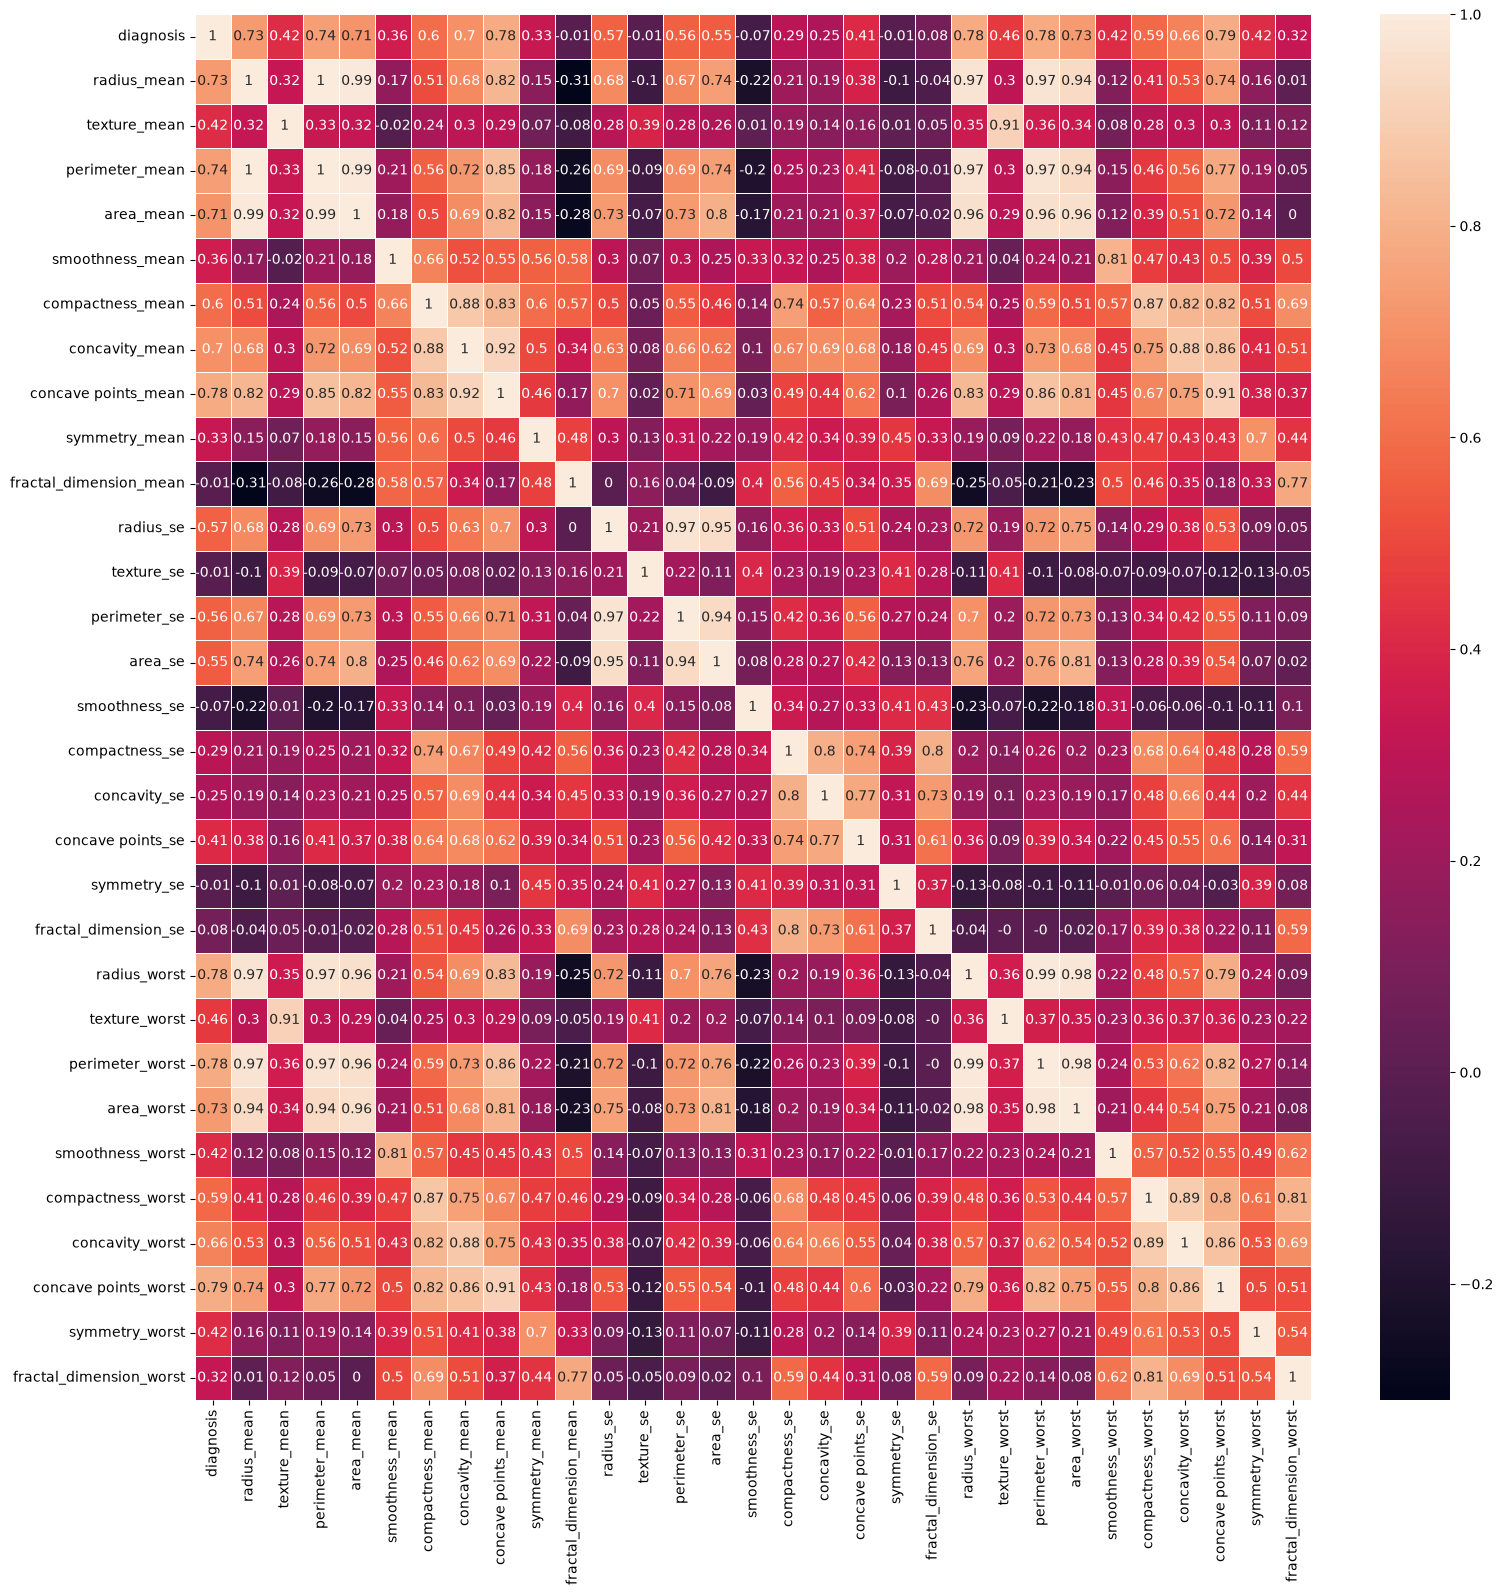

In [11]:
correlation_matriz = dados.corr().round(2)
fig, ax = plt.subplots(figsize=(18,18))
sb.heatmap(correlation_matriz,annot=True, linewidths=0.5, ax=ax)

### Com a matriz de correlação acima podemos ver que as mais correlacionadas com a variável alvo (diagnosis) são:
<h5>As características com maior associação ao diagnóstico estão relacionadas ao tamanho e o côncavo.

* radius_mean 0.73
* perimeter_mean 0.74
* concave points_mean 0.78

* radius_worst 0.78
* perimeter_worst 0.78
* concave points_worst 0.79
</h5>


## Usando as 30 preditivas e a variável-alvo (diagnosis)

In [12]:
Y = dados["diagnosis"]
X = dados.drop(columns="diagnosis")

print("Preditivas:", X.shape)
print("Alvo:", Y.shape)

Preditivas: (569, 30)
Alvo: (569,)


## Separação dados para treino e teste
- Separei 20% dos casos para teste e 80% para o treinamento.
- Utilizando random_state em 42, para garantir sempre a mesma quantidade na divisão dos dados. Sempre que o código é re-executado os mesmo registros são selecionados para treino e teste. 
- O stratify preservará a proporção de casos benignos e malignos.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Treino preditivas:", X_train.shape)
print("Teste preditivas:", X_test.shape)

Treino preditivas: (455, 30)
Teste preditivas: (114, 30)


In [14]:
modelo_arvore = DecisionTreeClassifier(random_state=42)
modelo_arvore.fit(X_train, Y_train)

print("Profundidade:", modelo_arvore.get_depth())
print("Quantidade de folhas:", modelo_arvore.get_n_leaves())

Profundidade: 8
Quantidade de folhas: 24


# Investigação de Overfitting:
Para averiguar se ocorreu um possível overfitting, foram realizadas previsões nos dados de treinamento e nos dados de teste. Com isso, podemos comparar o desempenho do modelo nos dados conhecidos e em dados não utilizados durante o treinamento.


In [15]:
#Dados de treino
Y_pred_train = modelo_arvore.predict(X_train)

#Dados de teste
Y_pred_test = modelo_arvore.predict(X_test)

## Matriz de Confusão

Matriz de Confusão:
 [[68  4]
 [ 4 38]]


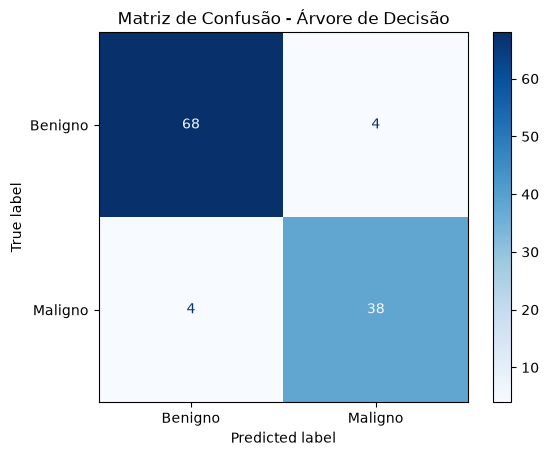

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_confusao = confusion_matrix(Y_test, Y_pred_test)
print("Matriz de Confusão:\n", matriz_confusao)
ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues")
plt.title("Matriz de Confusão - Árvore de Decisão")
plt.show()

Tivemos:
* 68 casos benignos (TN - True Negative)
* 4 casos benignos previstos como maligno 🚨​ (FP - False Positive) 
* 4 casos onde era **maligno**, mas foi previsto benigno (FN - False Negative) 🚨​🚨​
* 38 casos malignos (TP - True Positive)


#### <h5>Recall: Dos casos malignos, quantos foram detectados corretamente?</h5> 

In [17]:
from sklearn.metrics import recall_score

recall = recall_score(Y_test, Y_pred_test)

print("Recall:", f"{recall*100:.2f} %")

Recall: 90.48 %


### Precisão: Dos casos previstos como malignos, quantos de fato eram?

In [18]:
from sklearn.metrics import precision_score

precision = precision_score(Y_test, Y_pred_test)

print("Precision:", f"{precision*100:.2f}%")

Precision: 90.48%


### F1-score: O equilíbrio entre o Precision e Recall

In [19]:
from sklearn.metrics import f1_score

f1 = f1_score(Y_test, Y_pred_test)

print("F1-score:", f"{f1*100:.2f}%")

F1-score: 90.48%


### Acurácia: Quantos o modelo classificou corretamente?

In [20]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, Y_pred_test)
print("Accuracy:", f"{accuracy*100:.2f}%")

Accuracy: 92.98%


In [21]:
#Conclusão
print("Matrix de Confusão: \n",matriz_confusao)
print("Recall: ",f"{recall*100:.2f}%")
print("Precision: ",f"{precision*100:.2f}%")
print("F1-score: ",f"{f1*100:.2f}%")
print("Accuracy: ",f"{accuracy*100:.2f}%")

Matrix de Confusão: 
 [[68  4]
 [ 4 38]]
Recall:  90.48%
Precision:  90.48%
F1-score:  90.48%
Accuracy:  92.98%


### <h5> A coincidência do percentual 90,48% no recall, precisão e F1-Score aconteceu devido ao False Positive e o False Negative terem o valor 4. Parâmetros esses utilizados na formula para obtenção do recall, precisão, F1-Score </h5>

| Métrica   | Regressão Logística | Árvore sem restrições |
| --------- | ------------------: | --------------------: |
| TN        |              **71** |                    68 |
| FP        |               **1** |                     4 |
| FN        |               **3** |                     4 |
| TP        |              **39** |                    38 |
| Recall    |          **92,86%** |                90,48% |
| Precision |          **97,50%** |                90,48% |
| F1-score  |          **95,12%** |                90,48% |
| Accuracy  |          **96,49%** |                92,98% |


### Sem especificar o parâmetro max_depth para árvore de decisão, o modelo foi até uma profundidade de 8. E vimos que a performance da regressão logística foi bem melhor. (até agora)
* Mas, e se espeficificarmos o max_depth, e qual valor passar para o parâmetro? </br>
R: Vamos testar a performance de 1 a 8.

# Max_depth

## 1

In [22]:
modelo_arvore_n1 = DecisionTreeClassifier(max_depth=1, random_state=42)
modelo_arvore_n1.fit(X_train, Y_train)
print("Profundidade:", modelo_arvore_n1.get_depth())
print("Quantidade de folhas:", modelo_arvore_n1.get_n_leaves())

Profundidade: 1
Quantidade de folhas: 2


In [23]:
#Treino com profundidade 1
Y_pred_train_n1 = modelo_arvore_n1.predict(X_train)
#Teste com profundidade 1
Y_pred_test_n1 = modelo_arvore_n1.predict(X_test)

### <h3>Matriz de Confusão </h3>

Matriz de Confusão (Profundidade 1):
 [[70  2]
 [12 30]]


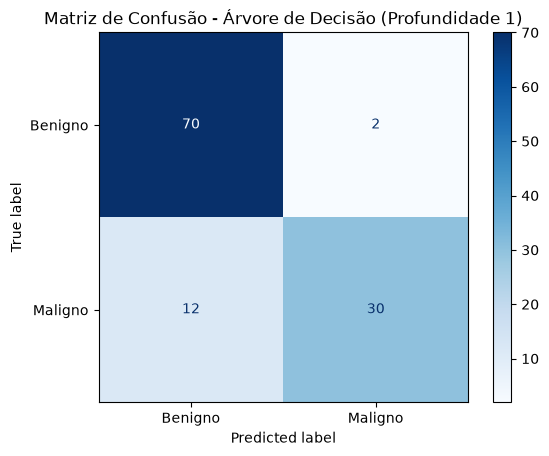

In [24]:
matriz_confusao_n1 = confusion_matrix(Y_test, Y_pred_test_n1)
print("Matriz de Confusão (Profundidade 1):\n", matriz_confusao_n1)

ConfusionMatrixDisplay(confusion_matrix=matriz_confusao_n1, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues")
plt.title("Matriz de Confusão - Árvore de Decisão (Profundidade 1)")
plt.show()

### <h3>Recall, Precisão, F1-Score e Acurácia</h3>

In [25]:
#Recall
recall_n1 = recall_score(Y_test, Y_pred_test_n1)
print("Recall (Profundidade 1): ", f"{recall_n1*100:.2f}%")

#Precisão
precision_n1 = precision_score(Y_test, Y_pred_test_n1)
print("Precisão (Profundidade 1):", f"{precision_n1*100:.2f}%")

#F1-score
f1_n1 = f1_score(Y_test, Y_pred_test_n1)
print("F1-score (Profundidade 1):", f"{f1_n1*100:.2f}%")

#Acurácia
accuracy_test_n1 = accuracy_score(Y_test, Y_pred_test_n1)
print("Acurácia teste (Profundidade 1):", f"{accuracy_test_n1*100:.2f}%")
accuracy_train_n1 = accuracy_score(Y_train, Y_pred_train_n1)
print("Acurácia treino (Profundidade 1):", f"{accuracy_train_n1*100:.2f}%")


Recall (Profundidade 1):  71.43%
Precisão (Profundidade 1): 93.75%
F1-score (Profundidade 1): 81.08%
Acurácia teste (Profundidade 1): 87.72%
Acurácia treino (Profundidade 1): 92.97%


# 2

In [26]:
modelo_arvore_n2 = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo_arvore_n2.fit(X_train, Y_train)

print("Profundidade:", modelo_arvore_n2.get_depth())
print("Quantidade de folhas:", modelo_arvore_n2.get_n_leaves())

Profundidade: 2
Quantidade de folhas: 4


In [27]:
Y_pred_train_n2 = modelo_arvore_n2.predict(X_train)
Y_pred_test_n2 = modelo_arvore_n2.predict(X_test)

## <h3>Matriz de Confusão</h3>

Matriz de Confusão (Profundidade 2):
 [[71  1]
 [ 8 34]]


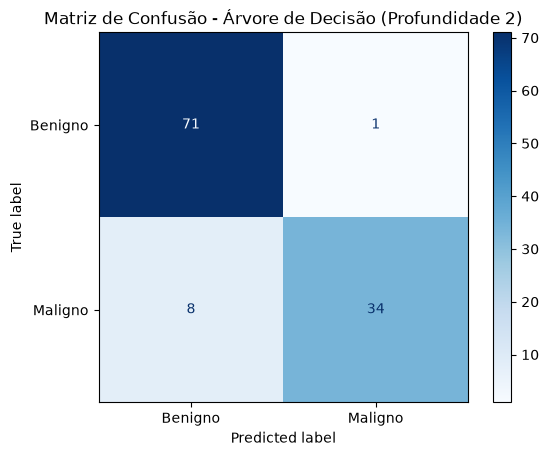

In [28]:
matriz_confusao_n2 = confusion_matrix(Y_test, Y_pred_test_n2)
print("Matriz de Confusão (Profundidade 2):\n", matriz_confusao_n2)

ConfusionMatrixDisplay(confusion_matrix=matriz_confusao_n2, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues")
plt.title("Matriz de Confusão - Árvore de Decisão (Profundidade 2)")
plt.show()

### <h3>Recall, Precisão, F1-Score e Acurácia</h3>

In [29]:
#Recall
recall_n2 = recall_score(Y_test, Y_pred_test_n2)
print("Recall (Profundidade 2): ", f"{recall_n2*100:.2f}%")

#Precisão
precision_n2 = precision_score(Y_test, Y_pred_test_n2)
print("Precisão (Profundidade 2): ", f"{precision_n2*100:.2f}%")

#F1-score
f1_n2 = f1_score(Y_test, Y_pred_test_n2)
print("F1-score (Profundidade 2): ", f"{f1_n2*100:.2f}%")

#Acurácia
accuracy_test_n2 = accuracy_score(Y_test, Y_pred_test_n2)
print("Acurácia teste (Profundidade 2): ", f"{accuracy_test_n2*100:.2f}%")
accuracy_train_n2 = accuracy_score(Y_train, Y_pred_train_n2)
print("Acurácia treino (Profundidade 2): ", f"{accuracy_train_n2*100:.2f}%")


Recall (Profundidade 2):  80.95%
Precisão (Profundidade 2):  97.14%
F1-score (Profundidade 2):  88.31%
Acurácia teste (Profundidade 2):  92.11%
Acurácia treino (Profundidade 2):  95.38%


# 3

In [30]:
modelo_arvore_n3 = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo_arvore_n3.fit(X_train, Y_train)
print("Profundidade:", modelo_arvore_n3.get_depth())
print("Quantidade de folhas:", modelo_arvore_n3.get_n_leaves())

#Treino com profundidade 3
Y_pred_train_n3 = modelo_arvore_n3.predict(X_train)
#Teste com profundidade 3
Y_pred_test_n3 = modelo_arvore_n3.predict(X_test)

Profundidade: 3
Quantidade de folhas: 8


## Matriz de Confusão

Matriz de Confusão (Profundidade 3):
 [[70  2]
 [ 9 33]]


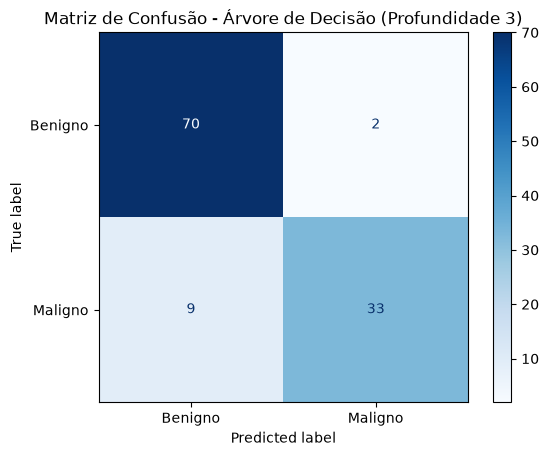

In [31]:
matriz_confusao_n3 = confusion_matrix(Y_test, Y_pred_test_n3)
print("Matriz de Confusão (Profundidade 3):\n", matriz_confusao_n3)

ConfusionMatrixDisplay(confusion_matrix=matriz_confusao_n3, display_labels=["Benigno", "Maligno"]).plot(cmap="Blues")
plt.title("Matriz de Confusão - Árvore de Decisão (Profundidade 3)")
plt.show()

### <h3>Recall, Precisão, F1-Score e Acurácia</h3>

In [32]:
#Recall
recall_n3 = recall_score(Y_test, Y_pred_test_n3)
print("Recall (Profundidade 3): ", f"{recall_n3*100:.2f}%")

#Precisão
precision_n3 = precision_score(Y_test, Y_pred_test_n3)
print("Precisão (Profundidade 3): ", f"{precision_n3*100:.2f}%")

#F1-score
f1_n3 = f1_score(Y_test, Y_pred_test_n3)
print("F1-score (Profundidade 3): ", f"{f1_n3*100:.2f}%")

#Acurácia
accuracy_test_n3 = accuracy_score(Y_test, Y_pred_test_n3)
print("Acurácia teste (Profundidade 3): ", f"{accuracy_test_n3*100:.2f}%")
accuracy_train_n3 = accuracy_score(Y_train, Y_pred_train_n3)
print("Acurácia treino (Profundidade 3): ", f"{accuracy_train_n3*100:.2f}%")

Recall (Profundidade 3):  78.57%
Precisão (Profundidade 3):  94.29%
F1-score (Profundidade 3):  85.71%
Acurácia teste (Profundidade 3):  90.35%
Acurácia treino (Profundidade 3):  96.70%


# <h3>Max_depth de 1 a 8</h3>

In [33]:
resultados = []

for profundidade in range(1,9):
    modelo_arvore = DecisionTreeClassifier(max_depth=profundidade, random_state=42)
    modelo_arvore.fit(X_train, Y_train)
    
    Y_pred_test_prof = modelo_arvore.predict(X_test)
    Y_pred_train_prof = modelo_arvore.predict(X_train)

    matriz_confusao_prof = confusion_matrix(Y_test, Y_pred_test_prof)
    tn, fp, fn, tp = matriz_confusao_prof.ravel()
    recall_prof = recall_score(Y_test, Y_pred_test_prof)
    precision_prof = precision_score(Y_test, Y_pred_test_prof)
    f1_prof = f1_score(Y_test, Y_pred_test_prof)
    accuracy_test_prof = accuracy_score(Y_test, Y_pred_test_prof)
    accuracy_train_prof = accuracy_score(Y_train, Y_pred_train_prof)

    print(f"Profundidade: {profundidade}")
    print("Matriz de Confusão:\n", matriz_confusao_prof)
    print("Recall: ", f"{recall_prof*100:.2f}%")
    print("Precisão: ", f"{precision_prof*100:.2f}%")
    print("F1-score: ", f"{f1_prof*100:.2f}%")
    print("Acurácia teste: ", f"{accuracy_test_prof*100:.2f}%")
    print("Acurácia treino: ", f"{accuracy_train_prof*100:.2f}%")
    print("-"*50)

    resultados.append({
            "Depth": profundidade,
            "FN": fn,
            "FP": fp,
            "Acurácia Treino": accuracy_train_prof,
            "Acurácia Teste": accuracy_test_prof,
            "Recall": recall_prof,
            "Precisão": precision_prof,
            "F1": f1_prof
        })


tabela = pd.DataFrame(resultados)
tabela = tabela.reset_index(drop=True)

tabela[["Acurácia Treino", "Acurácia Teste", "Recall", "Precisão", "F1"]] = (
    tabela[["Acurácia Treino", "Acurácia Teste", "Recall", "Precisão", "F1"]]
    .apply(lambda col: col.map(lambda x: f"{x * 100:.2f}%"))
)

display(tabela.style.hide(axis="index"))

Profundidade: 1
Matriz de Confusão:
 [[70  2]
 [12 30]]
Recall:  71.43%
Precisão:  93.75%
F1-score:  81.08%
Acurácia teste:  87.72%
Acurácia treino:  92.97%
--------------------------------------------------
Profundidade: 2
Matriz de Confusão:
 [[71  1]
 [ 8 34]]
Recall:  80.95%
Precisão:  97.14%
F1-score:  88.31%
Acurácia teste:  92.11%
Acurácia treino:  95.38%
--------------------------------------------------
Profundidade: 3
Matriz de Confusão:
 [[70  2]
 [ 9 33]]
Recall:  78.57%
Precisão:  94.29%
F1-score:  85.71%
Acurácia teste:  90.35%
Acurácia treino:  96.70%
--------------------------------------------------
Profundidade: 4
Matriz de Confusão:
 [[70  2]
 [ 8 34]]
Recall:  80.95%
Precisão:  94.44%
F1-score:  87.18%
Acurácia teste:  91.23%
Acurácia treino:  98.24%
--------------------------------------------------
Profundidade: 5
Matriz de Confusão:
 [[70  2]
 [ 7 35]]
Recall:  83.33%
Precisão:  94.59%
F1-score:  88.61%
Acurácia teste:  92.11%
Acurácia treino:  98.68%
-----------

Depth,FN,FP,Acurácia Treino,Acurácia Teste,Recall,Precisão,F1
1,12,2,92.97%,87.72%,71.43%,93.75%,81.08%
2,8,1,95.38%,92.11%,80.95%,97.14%,88.31%
3,9,2,96.70%,90.35%,78.57%,94.29%,85.71%
4,8,2,98.24%,91.23%,80.95%,94.44%,87.18%
5,7,2,98.68%,92.11%,83.33%,94.59%,88.61%
6,6,3,99.34%,92.11%,85.71%,92.31%,88.89%
7,5,2,99.56%,93.86%,88.10%,94.87%,91.36%
8,4,4,100.00%,92.98%,90.48%,90.48%,90.48%


# Comparativo da Acurácia de Treino vs. Teste

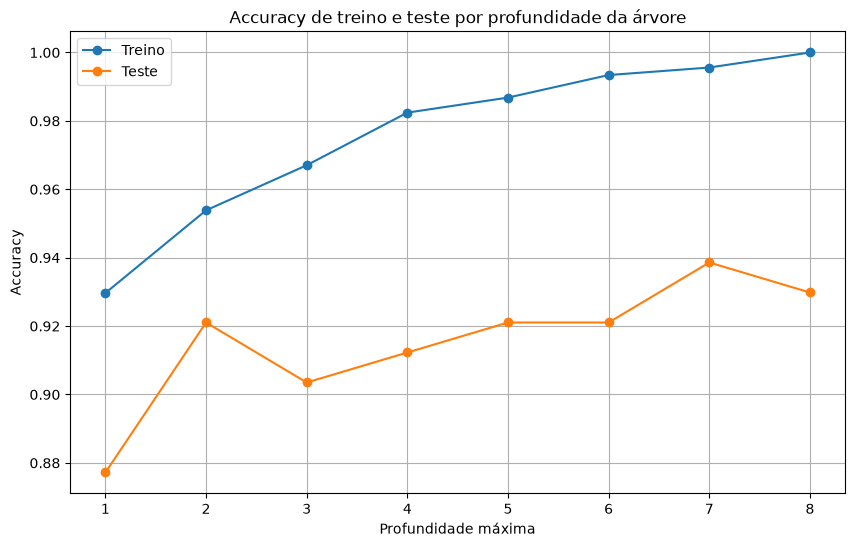

In [34]:
plt.figure(figsize=(10, 6))

plt.plot(range(1, 9), [r["Acurácia Treino"] for r in resultados], marker="o", label="Treino")
plt.plot(range(1, 9), [r["Acurácia Teste"] for r in resultados], marker="o", label="Teste")

plt.xlabel("Profundidade máxima")
plt.ylabel("Accuracy")
plt.title("Accuracy de treino e teste por profundidade da árvore")
plt.xticks(range(1, 9))
plt.legend()
plt.grid(True)

plt.show()

# Validação Cruzada

In [35]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

modelo_cv = DecisionTreeClassifier(max_depth=7, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_recall = cross_val_score(modelo_cv, X_train, Y_train, cv=cv, scoring="recall")

print("Recall de cada fold:", scores_recall)
print(f"Recall médio: {scores_recall.mean() * 100:.2f}%")
print(f"Desvio padrão: {scores_recall.std() * 100:.2f}%")


Recall de cada fold: [0.85294118 1.         0.82352941 0.88235294 0.91176471]
Recall médio: 89.41%
Desvio padrão: 6.06%


* Nas 5 validações feitas no conjunto de treinamento, a média do Recall é de **89,41%**.
* Um desvio padrão de **6,06%**, indica que o desempenho teve uma variabilidade entre os diferentes folds, dependendo dos registros utilizados para validação.

## GridSearchCV

In [36]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "max_depth": range(1, 9)
}

modelo_grid = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(modelo_grid, parametros, cv=cv, scoring="recall")

grid_search.fit(X_train, Y_train)

print("Melhor parâmetro:", grid_search.best_params_)
print(f"Melhor Recall médio: {grid_search.best_score_ * 100:.2f}%")

Melhor parâmetro: {'max_depth': 7}
Melhor Recall médio: 89.41%


#### <h5>Ao utilizar o GridSearch, usando somente as variáveis de treinamento (X_train/Y_train) e priorizando o recall, também ficou constatado que a melhor opção de profundidade é **7** </h5>

In [37]:
modelo_arvore_final = DecisionTreeClassifier(
    max_depth=grid_search.best_params_["max_depth"],
    random_state=42
)

modelo_arvore_final.fit(X_train, Y_train)

Y_pred_final = modelo_arvore_final.predict(X_test)

matriz_final = confusion_matrix(Y_test, Y_pred_final)

recall_final = recall_score(Y_test, Y_pred_final)
precision_final = precision_score(Y_test, Y_pred_final)
f1_final = f1_score(Y_test, Y_pred_final)
accuracy_final = accuracy_score(Y_test, Y_pred_final)

print("Matriz de Confusão:")
print(matriz_final)

print(f"Recall:    {recall_final * 100:.2f}%")
print(f"Precisão:  {precision_final * 100:.2f}%")
print(f"F1-score:  {f1_final * 100:.2f}%")
print(f"Acurácia:  {accuracy_final * 100:.2f}%")

Matriz de Confusão:
[[70  2]
 [ 5 37]]
Recall:    88.10%
Precisão:  94.87%
F1-score:  91.36%
Acurácia:  93.86%


## Feature Importance
Após avaliação do modelo final de Árvore de Decisão, vamos realizar a análise da importância das variáveis utilizadas pelo modelo. Com a análise a seguir, será possível identificar quais features tiveram maior influência nas decisões realizadas pela árvore.

In [38]:
importancia = modelo_arvore_final.feature_importances_
print("Importância das features:", importancia)
print("Quantidade de features:", len(X.columns))
print("Quantidade de importâncias:", len(importancia))

Importância das features: [0.         0.0558373  0.01142259 0.02275756 0.01142259 0.00634589
 0.         0.         0.         0.         0.         0.00634589
 0.         0.00226473 0.         0.         0.         0.
 0.00713912 0.         0.         0.01015957 0.7373698  0.01581872
 0.04138802 0.         0.0031073  0.06862092 0.         0.        ]
Quantidade de features: 30
Quantidade de importâncias: 30


Associando o valor da importância a cada feature:

In [39]:
importancias = pd.DataFrame({
    "Feature": X.columns,
    "Importancia": modelo_arvore_final.feature_importances_
})

importancias = importancias.sort_values(by="Importancia", ascending=False).reset_index(drop=True)

display(importancias)

,Feature,Importancia
0,perimeter_worst,0.737370
1,concave points_worst,0.068621
2,texture_mean,0.055837
3,smoothness_worst,0.041388
4,area_mean,0.022758
5,area_worst,0.015819
6,smoothness_mean,0.011423
7,perimeter_mean,0.011423
8,texture_worst,0.010160
9,symmetry_se,0.007139


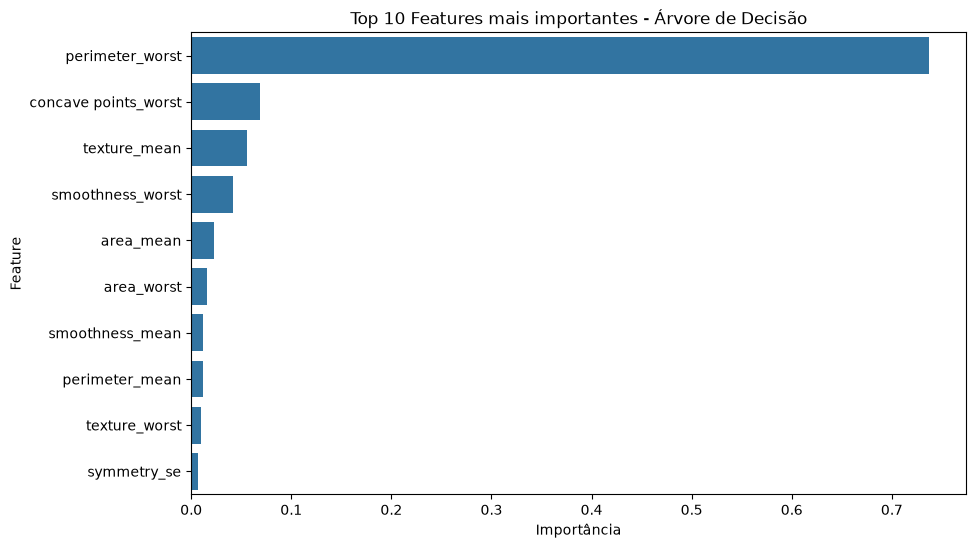

In [40]:

plt.figure(figsize=(10, 6))

sb.barplot(data= importancias.head(10), x="Importancia", y="Feature")

plt.title("Top 10 Features mais importantes - Árvore de Decisão")
plt.xlabel("Importância")
plt.ylabel("Feature")

plt.show()

A análise de Feature Importance demonstra que perimeter_worst foi a característica de maior influência nas decisões da Árvore de Decisão, concentrando aproximadamente 73,74% da importância calculada pelo modelo. Outras características, como concave points_worst, texture_mean e smoothness_worst, também contribuíram para as classificações, porém com menor importância.</br>

Algumas features que vimos com uma alta correlação com o diagnóstico, nos passos iniciais da análise exploratória dos dados, receberam importância zero na árvore indicando que não foram utilizadas para a decisão.

## Explicabilidade com SHAP

Já o SHAP utilizaremos para analisar como as variáveis contribuíram para as previsões realizadas pelo modelo de Árvore de Decisão.

Enquanto o Feature Importance apresentou uma visão geral das variáveis mais utilizadas pelo modelo, o SHAP permitirá analisar a direção e a intensidade da contribuição de cada feature nas previsões.

In [41]:
import shap, numpy as np

explainer = shap.TreeExplainer(modelo_arvore_final)
print(explainer.expected_value)
shap_values = explainer.shap_values(X_test)
#pacientes / features / classes
print(shap_values.shape)

c:\Users\carme\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[0.62637363 0.37362637]
(114, 30, 2)


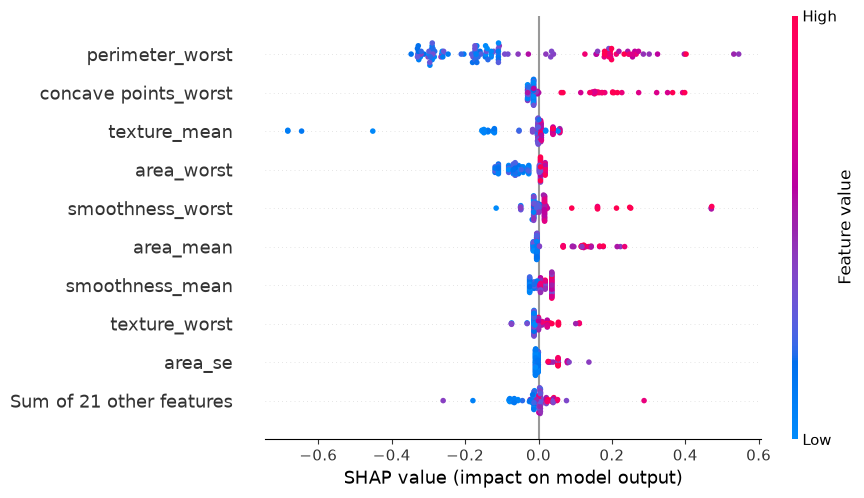

In [42]:
shap_maligno = shap.Explanation(values=shap_values[:, :, 1], 
    base_values=np.repeat(explainer.expected_value[1],len(X_test)),
    data=X_test.values,
    feature_names=X_test.columns
)
# Visualização das 10 features com maior impacto nas previsões
shap.plots.beeswarm(shap_maligno, max_display=10)

O gráfico SHAP demonstra que perimeter_worst apresentou o maior impacto global nas previsões da Árvore de Decisão, resultado consistente com a análise de Feature Importance. Valores elevados dessa característica tenderam a contribuir positivamente para a saída correspondente à classe maligna, enquanto valores menores apresentaram predominantemente contribuições no sentido oposto.

Características como concave points_worst, texture_mean, area_worst e smoothness_worst também apresentaram influência relevante nas previsões. A análise SHAP complementa a Feature Importance ao permitir observar não apenas quais variáveis foram mais relevantes para o modelo, mas também a direção de suas contribuições.

Essas relações representam o comportamento do modelo treinado e não devem ser interpretadas isoladamente como relações causais ou conclusões clínicas.

# Amostra Individual
A amostra abaixo foi selecionda por possuir o diagnóstico real de câncer maligno, e corretamente prevista pelo modelo como maligno. Será implementado o gráfico waterfall do SHAP para demonstrar quais características dessa amostra mais contribuíram individualmente para a previsão. 

In [43]:
# Índices dos casos malignos corretamente classificados
indices_tp = Y_test[(Y_test == 1) & (Y_pred_final == 1)].index
indice_caso = indices_tp[0]

print("Índice escolhido:", indice_caso)
print("Diagnóstico real:", Y_test.loc[indice_caso])

Índice escolhido: 250
Diagnóstico real: 1


Posição no X_test:  1
Previsão da árvore: 1
Probabilidades [Benigno, Maligno]: [0. 1.]


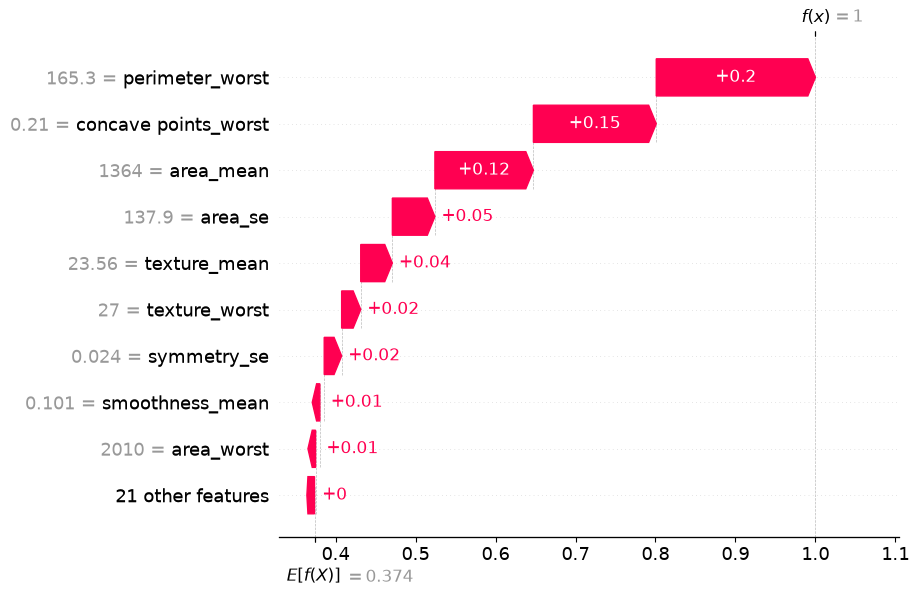

In [45]:
posicao_caso = X_test.index.get_loc(indice_caso)
print("Posição no X_test: ", posicao_caso)
print("Previsão da árvore:", modelo_arvore_final.predict(X_test.loc[[indice_caso]])[0])
print("Probabilidades [Benigno, Maligno]:", modelo_arvore_final.predict_proba(X_test.loc[[indice_caso]])[0])

shap.plots.waterfall(shap_maligno[posicao_caso], max_display=10)

**"perimeter_worst"**, **"concave points_worst"** e **"area_mean"** apresentaram as maiores contribuições positivas para a saída correspondente à classe maligna. Entre elas, **"perimeter_worst"** foi a feature de maior impacto individual, com contribuição SHAP de aproximadamente +0,20.

O resultado da amostra individual foi condizente com as análises globais de Feature Importance e SHAP, nas quais a feature **perimeter_worst** foi a que apresentou a maior contribuição para o resultado.


# Conclusão - Árvore de Decisão

O primeiro modelo de Árvore de Decisão, treinado sem especificar o parâmetro máximo de profundidade (max_depth), atingiu 100% de acurácia no treinamento, porém, somente 92,98% de acurácia no teste. Essa diferença observada poderia significar um caso de overfitting, o que motivou uma investigação avaliando diferentes profundidades e seus respectivos resultados de acurácia, recall, f1 e matriz de confusão. Também foi aplicada uma validação cruzada com **StratifiedKFold** e **GridSearchCV**, utilizando Recall como a métrica de seleção devido à necessidade de priorizar a identificação correta dos casos malignos. O processo selecionou max_depth=7.

A Árvore de Decisão final apresentou acurácia de 93,86%, Recall de 88,10%, Precisão de 94,87% e F1-score de 91,36%. Na matriz de confusão foram observados 70 verdadeiros negativos, 37 verdadeiros positivos, 2 falsos positivos e **5 falsos negativos**.

Na análise de explicabilidade, **perimeter_worst** apresentou a maior Feature Importance e também forte influência nas explicações produzidas pelo SHAP. A análise de uma amostra individual de um verdadeiro positivo demonstrou como diferentes características contribuíram para a classificação realizada pelo modelo.

Apesar do modelo ter apresentado um bom desempenho, a presença de falsos negativos demonstra que há uma limitação na empregabilidade desse modelo na vida real. Ele deveria ser considerado somente como uma ferramenta de apoio, não substituindo ou sendo priorizado acima da avaliação de um profissional de saúde.





